In [1]:
#import libraries
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from preprocessing import load_adult, onehot
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

In [2]:
#loading the dataset
trainDf, testDf = load_adult()

print(trainDf.shape)
print(testDf.shape)

(32561, 15)
(16281, 15)


In [3]:
#preprocessing features and seperating labels
xTrain, xTest = onehot(trainDf, testDf)

yTrain = trainDf["income"]
yTest = testDf["income"]

print(xTrain.shape)
print(xTest.shape)

(32561, 108)
(16281, 108)


In [4]:
#training initial random forest model
rfModel = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rfModel.fit(xTrain, yTrain)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [5]:
#evaluating initial random forest model
yPred = rfModel.predict(xTest)

initialAccuracy = accuracy_score(yTest, yPred)

print("Random Forest Accuracy:", initialAccuracy)
print(classification_report(yTest, yPred))
print(confusion_matrix(yTest, yPred))

Random Forest Accuracy: 0.850991953811191
              precision    recall  f1-score   support

           0       0.88      0.93      0.90     12435
           1       0.72      0.61      0.66      3846

    accuracy                           0.85     16281
   macro avg       0.80      0.77      0.78     16281
weighted avg       0.85      0.85      0.85     16281

[[11507   928]
 [ 1498  2348]]


In [6]:
#setting up grid search and cross validation
paramGrid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [7]:
#grid search
grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    paramGrid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1
)

grid.fit(xTrain, yTrain)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [10, 20, None],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100]},
             return_train_score=True, scoring='accuracy')

In [8]:
#grid search results
trainAcc = grid.cv_results_["mean_train_score"][grid.best_index_]
valAcc = grid.best_score_

print("Best parameters:", grid.best_params_)
print(f"Training accuracy: {trainAcc:.1%}")
print(f"Validation accuracy: {valAcc:.1%}")

Best parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}
Training accuracy: 90.5%
Validation accuracy: 86.4%


In [9]:
#evaluating random forest model after  grid search and cross validation
yPredTuned = grid.predict(xTest)

testAcc = accuracy_score(yTest, yPredTuned)

print(f"Tuned Random Forest Test Accuracy: {testAcc:.1%}")

Tuned Random Forest Test Accuracy: 86.3%


In [10]:
#model result summary
results = pd.DataFrame({
    "Metric": [
        "Initial Test Accuracy",
        "Best Number of Trees",
        "Best Maximum Depth",
        "Best Minimum Samples to Split",
        "Training Accuracy",
        "Cross-Validation Accuracy",
        "Tuned Test Accuracy"
    ],
    "Result": [
        f"{initialAccuracy:.2%}",
        grid.best_params_["n_estimators"],
        grid.best_params_["max_depth"],
        grid.best_params_["min_samples_split"],
        f"{trainAcc:.2%}",
        f"{valAcc:.2%}",
        f"{testAcc:.2%}"
    ]
})

display(results)

,Metric,Result
0,Initial Test Accuracy,85.10%
1,Best Number of Trees,100
2,Best Maximum Depth,20
3,Best Minimum Samples to Split,5
4,Training Accuracy,90.50%
5,Cross-Validation Accuracy,86.44%
6,Tuned Test Accuracy,86.32%


In [11]:
#function to introduce label noise
def addLabelNoise(y, noiseLevel, randomState=42):
    rng = np.random.default_rng(randomState)
    yNoisy = y.copy().to_numpy()

    nFlip = int(len(yNoisy) * noiseLevel)
    flipIndices = rng.choice(len(yNoisy), size=nFlip, replace=False)

    yNoisy[flipIndices] = 1 - yNoisy[flipIndices]

    return yNoisy

In [12]:
#repeating noise experiments with different random seeds
noiseLevels = [0, 0.1, 0.2, 0.3, 0.4]
seeds = [0, 1, 2, 3, 4]
repeatedResults = []

for noiseLevel in noiseLevels:
    for seed in seeds:
        yTrainNoisy = addLabelNoise(yTrain, noiseLevel, randomState=seed)

        model = RandomForestClassifier(
            **grid.best_params_,
            random_state=42,
            n_jobs=-1
        )

        model.fit(xTrain, yTrainNoisy)
        yPred = model.predict(xTest)

        accuracy = accuracy_score(yTest, yPred)

        repeatedResults.append({
            "Noise Level": noiseLevel,
            "Seed": seed,
            "Accuracy": accuracy,
            "Error Rate": 1 - accuracy,
            "Precision": precision_score(yTest, yPred),
            "Recall": recall_score(yTest, yPred),
            "F1 Score": f1_score(yTest, yPred)
        })

repeatedDf = pd.DataFrame(repeatedResults)

summaryDf = repeatedDf.groupby("Noise Level")[
    ["Accuracy", "Error Rate", "Precision", "Recall", "F1 Score"]
].agg(["mean", "std"])

display(summaryDf)


Accuracy           Error Rate           Precision            \
                 mean       std       mean       std      mean       std   
Noise Level                                                                
0.0          0.863153  0.000000   0.136847  0.000000  0.777055  0.000000   
0.1          0.862760  0.000856   0.137240  0.000856  0.771756  0.002378   
0.2          0.858878  0.000868   0.141122  0.000868  0.755924  0.002795   
0.3          0.852048  0.002237   0.147952  0.002237  0.737657  0.007775   
0.4          0.818586  0.006607   0.181414  0.006607  0.637537  0.021121   

               Recall            F1 Score            
                 mean       std      mean       std  
Noise Level                                          
0.0          0.589964  0.000000  0.670706  0.000000  
0.1          0.595008  0.003302  0.671949  0.002439  
0.2          0.594592  0.002748  0.665617  0.002167  
0.3          0.580031  0.005116  0.649396  0.004764  
0.4          0.540094  0.016377  0.584470  0.011099

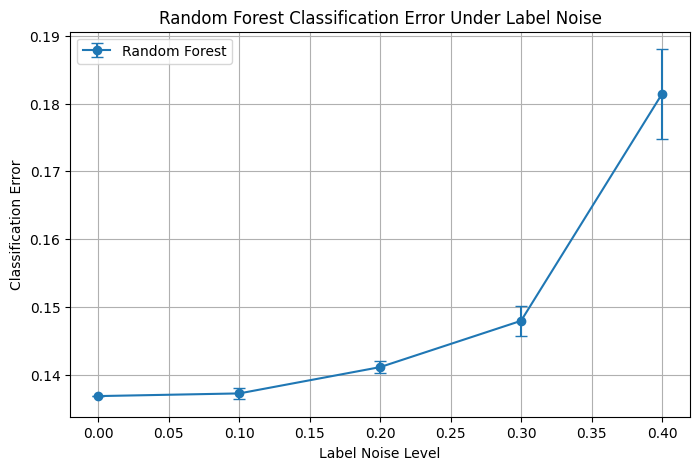

In [13]:
#plotting mean classification error against label noise
meanError = summaryDf["Error Rate"]["mean"]
stdError = summaryDf["Error Rate"]["std"]

plt.figure(figsize=(8, 5))

plt.errorbar(
    noiseLevels,
    meanError,
    yerr=stdError,
    marker="o",
    capsize=4,
    label="Random Forest"
)

plt.xlabel("Label Noise Level")
plt.ylabel("Classification Error")
plt.title("Random Forest Classification Error Under Label Noise")
plt.legend()
plt.grid(True)
plt.show()